# Análise Exploratória de Dados (EDA) - Olist E-Commerce

Neste notebook realizamos:
1. **Verificação de arquivos disponíveis** no bucket S3 (camada `bronze`).
2. **Carregamento dos dados em formato Parquet** utilizando as funções do módulo `src.utils` (`iniciar_cessao_aws`, `listar_arquivos_s3` e `carregar_parquet_s3`).
3. **Inspeção de estrutura, dimensões e tipos de dados** de cada tabela.
4. **Exploração inicial e qualidade dos dados** (valores ausentes, duplicados e amostras).

## Imports de bibliotecas

In [1]:
import os
import sys
from pathlib import Path
import pandas as pd
import numpy as np
from dotenv import load_dotenv, find_dotenv

# Configurações do pandas para melhor visualização
pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 1000)

# Adiciona raiz do projeto ao sys.path para importar src.utils
notebook_dir = Path.cwd().resolve()
project_root = notebook_dir.parents[1] if notebook_dir.name == 'notebooks' else notebook_dir.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.utils import iniciar_cessao_aws, carregar_parquet_s3, listar_arquivos_s3


## Configuração do Ambiente e Conexão AWS S3

In [2]:

# Carrega variáveis do .env
load_dotenv(find_dotenv())
BUCKET_NAME = os.getenv('BUCKET_NAME')
AWS_REGION = os.getenv('AWS_REGION', 'us-east-1')

# Inicializa sessão e cliente S3
session = iniciar_cessao_aws()
s3_client = session.client('s3')

print(f" Conectado ao S3!")
print(f" - Bucket: {BUCKET_NAME}")
print(f" - Região: {AWS_REGION}")

 Conectado ao S3!
 - Bucket: postech-challenge-datascience-004
 - Região: us-east-1


## Verificar Todos os Arquivos Parquet Disponíveis no S3

In [3]:
# Lista todos os arquivos na camada bronze usando listar_arquivos_s3 de utils
arquivos_bronze = listar_arquivos_s3(s3_client, BUCKET_NAME, prefixo='bronze/')

# Cria DataFrame de resumo dos arquivos disponíveis
lista_resumo = []
for chave in arquivos_bronze:
    obj_meta = s3_client.head_object(Bucket=BUCKET_NAME, Key=chave)
    nome_arquivo = Path(chave).name
    nome_tabela = Path(chave).stem
    tamanho_mb = obj_meta['ContentLength'] / (1024 * 1024)
    modificado = obj_meta['LastModified'].strftime('%Y-%m-%d %H:%M:%S')
    lista_resumo.append({
        'Tabela': nome_tabela,
        'Arquivo': nome_arquivo,
        'Chave S3': chave,
        'Tamanho (MB)': round(tamanho_mb, 2),
        'Última Modificação': modificado
    })

df_catalogo = pd.DataFrame(lista_resumo)
print(f"Total de arquivos Parquet encontrados na camada Bronze: {len(df_catalogo)}\n")
display(df_catalogo[['Tabela', 'Tamanho (MB)', 'Última Modificação']])

Total de arquivos Parquet encontrados na camada Bronze: 9



,Tabela,Tamanho (MB),Última Modificação
0,olist_customers_dataset,6.68,2026-10-24 19:09:17
1,olist_geolocation_dataset,16.24,2026-10-24 19:09:19
2,olist_order_items_dataset,6.24,2026-10-24 19:09:20
3,olist_order_payments_dataset,3.66,2026-10-24 19:09:21
4,olist_order_reviews_dataset,9.16,2026-10-24 19:09:22
5,olist_orders_dataset,10.28,2026-10-24 19:09:23
6,olist_products_dataset,1.34,2026-10-24 19:09:25
7,olist_sellers_dataset,0.13,2026-10-24 19:09:25
8,product_category_name_translation,0.00,2026-10-24 19:09:25


## Carregamento dos Parquets

Podemos carregar individualmente qualquer tabela com:
```python
df = carregar_parquet_s3(s3_client, BUCKET_NAME, nome_tabela='olist_customers_dataset', camada='bronze')
```
Ou carregar todas as tabelas em um dicionário para exploração unificada.

In [4]:
# Dicionário com todos os DataFrames carregados do S3
dfs = {}

for item in lista_resumo:
    tabela = item['Tabela']
    # Carrega utilizando a função do utils
    dfs[tabela] = carregar_parquet_s3(
        s3_client=s3_client,
        bucket=BUCKET_NAME,
        nome_tabela=tabela,
        camada='bronze'
    )

print(f"\n🎉 {len(dfs)} tabelas carregadas com sucesso na memória!")

Lendo: s3://postech-challenge-datascience-004/bronze/olist_customers_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_geolocation_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_order_items_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_order_payments_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_order_reviews_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_orders_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_products_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/olist_sellers_dataset.parquet
Lendo: s3://postech-challenge-datascience-004/bronze/product_category_name_translation.parquet

🎉 9 tabelas carregadas com sucesso na memória!


## Visão Geral das Dimensões e Metadados das Tabelas

In [5]:
# Tabela comparativa de dimensões e contagem de nulos
info_tabelas = []
for nome, df in dfs.items():
    n_nulos = df.isna().sum().sum()
    mem_mb = df.memory_usage(deep=True).sum() / (1024 * 1024)
    info_tabelas.append({
        'Tabela': nome,
        'Qtd Linhas': df.shape[0],
        'Qtd Colunas': df.shape[1],
        'Total Nulos': n_nulos,
        'Memória (MB)': round(mem_mb, 2)
    })

df_info = pd.DataFrame(info_tabelas)
display(df_info)

,Tabela,Qtd Linhas,Qtd Colunas,Total Nulos,Memória (MB)
0,olist_customers_dataset,99441,5,0,11.03
1,olist_geolocation_dataset,1000163,5,0,50.12
2,olist_order_items_dataset,112650,7,0,18.37
3,olist_order_payments_dataset,103886,5,0,8.11
4,olist_order_reviews_dataset,99224,7,145903,17.84
5,olist_orders_dataset,99441,8,4908,21.95
6,olist_products_dataset,32951,9,2448,3.73
7,olist_sellers_dataset,3095,4,0,0.22
8,product_category_name_translation,71,2,0,0.00


## Inspeção Inicial das Tabelas

In [6]:
# 1. Clientes
print("=== olist_customers_dataset ===")
display(dfs['olist_customers_dataset'].head(3))

# 2. Pedidos
print("=== olist_orders_dataset ===")
display(dfs['olist_orders_dataset'].head(3))

# 3. Itens do Pedido
print("=== olist_order_items_dataset ===")
display(dfs['olist_order_items_dataset'].head(3))

# 4. Pagamentos
print("=== olist_order_payments_dataset ===")
display(dfs['olist_order_payments_dataset'].head(3))

# 5. Produtos
print("=== olist_products_dataset ===")
display(dfs['olist_products_dataset'].head(3))

=== olist_customers_dataset ===


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP


=== olist_orders_dataset ===


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00


=== olist_order_items_dataset ===


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.9,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.9,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.0,17.87


=== olist_order_payments_dataset ===


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71


=== olist_products_dataset ===


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0


## EDA reviews

In [7]:
df_review = dfs['olist_order_reviews_dataset']

print("Distribuição avaliações dos pedidos:")
display(df_review['review_score'].value_counts(dropna=False))


Distribuição avaliações dos pedidos:


review_score
5    57328
4    19142
1    11424
3     8179
2     3151
Name: count, dtype: int64

In [8]:
list(df_review.columns)

['review_id',
 'order_id',
 'review_score',
 'review_comment_title',
 'review_comment_message',
 'review_creation_date',
 'review_answer_timestamp']

In [9]:
df_review.head(5)

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [10]:
#filtrando apenas o que for relevante para o modelo num primeiro momento: 
mensagens  = df_review[['review_score','order_id','review_comment_message',]]

mapa_avaliacoes = {
    1: "negativa",
    2: "negativa",
    3: "negativa",
    4: "positiva",
    5: "positiva"
}

# Criando a nova coluna
mensagens["avaliacao"] = mensagens["review_score"].map(mapa_avaliacoes)
mensagens = mensagens.dropna(subset=["review_comment_message"])
mensagens = mensagens.drop(columns=["review_score"])
print(mensagens)

                               order_id                             review_comment_message avaliacao
3      658677c97b385a9be170737859d3511b              Recebi bem antes do prazo estipulado.  positiva
4      8e6bfb81e283fa7e4f11123a3fb894f1  Parabéns lojas lannister adorei comprar pela I...  positiva
9      b9bf720beb4ab3728760088589c62129  aparelho eficiente. no site a marca do aparelh...  positiva
12     9d6f15f95d01e79bd1349cc208361f09    Mas um pouco ,travando...pelo valor ta Boa.\r\n  positiva
15     e51478e7e277a83743b6f9991dbfa3fb  Vendedor confiável, produto ok e entrega antes...  positiva
...                                 ...                                                ...       ...
99205  d398e9c82363c12527f71801bf0e6100  para este produto recebi de acordo com a compr...  positiva
99208  509b86c65fe4e2ad5b96408cfef9755e  Entregou dentro do prazo. O produto chegou em ...  positiva
99215  d5cb12269711bd1eaf7eed8fd32a7c95  O produto não foi enviado com NF, não existe v... 

In [11]:
mensagens.isna().sum()

order_id                  0
review_comment_message    0
avaliacao                 0
dtype: int64

In [12]:
#Verificando o tamanho da base atual menos a diferença dos nulos 
print(f'base inicia {df_review.shape[0] }')
print(f'mensagem após limpeza {mensagens.shape[0]}')
print(f'nulos : {df_review['review_comment_message'].isna().sum()}')
print('diferença ')
df_review.shape[0] - mensagens.shape[0] - df_review['review_comment_message'].isna().sum()

base inicia 99224
mensagem após limpeza 40977
nulos : 58247
diferença 


np.int64(0)

In [13]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

def nuvem_palavras(texto,coluna_texto,avaliacao):
    texto_avaliacao = texto.query(f"avaliacao == '{avaliacao}'")[coluna_texto]

    texto_unido = ' '.join(texto_avaliacao)
    nuvem_palavras =  WordCloud(width=800,height=500,max_font_size=110,collocations=False).generate(texto_unido)
    
    plt.figure(figsize=(10,7))
    plt.imshow(nuvem_palavras,interpolation='bilinear')
    plt.axis('off')
    plt.show()


palavras mais usadas positivo e negativo: 

negativa


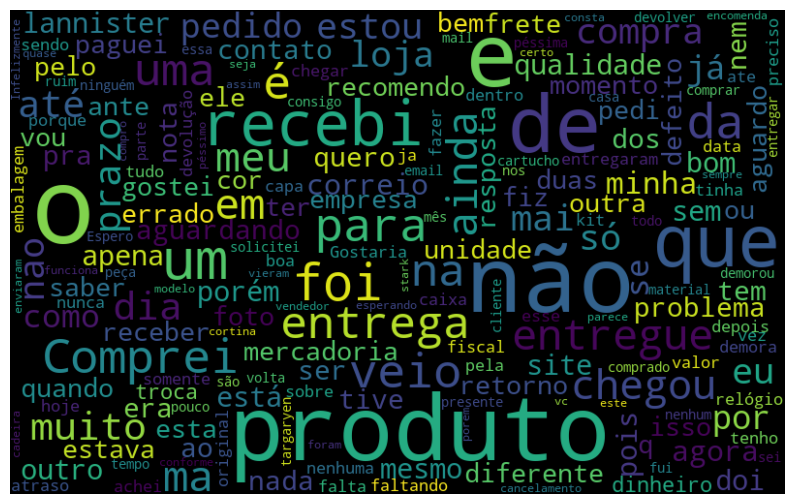

postiva


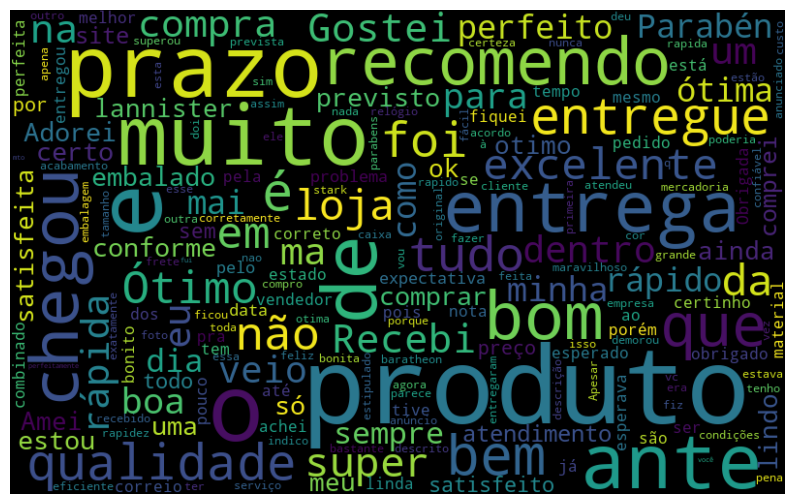

In [14]:
print('negativa')
nuvem_palavras(mensagens,'review_comment_message','negativa')
print('postiva')
nuvem_palavras(mensagens,'review_comment_message','positiva')

### LIMPEZA DA BASE

Vou usara agora a biblioteca NLTK para fazer a limpeza dos textos, stopwords, pontuação etc

In [15]:
mensagens = mensagens.rename(columns={'review_comment_message': 'review'})

In [16]:
import nltk

#para baixar 
#nltk.download('all')

In [17]:
from nltk import tokenize

#calcular frequencia da aparição das palavras

token_espaco = tokenize.WhitespaceTokenizer()


todas_palavras = ' '.join([texto for texto in mensagens.review])
token_frase = token_espaco.tokenize(todas_palavras)

frequencia = nltk.FreqDist(token_frase)

avaliação de palavras mais usadas

In [18]:


df_frequencia = pd.DataFrame({'Palavra' : list(frequencia.keys()),
                              'Frequencia' : list(frequencia.values())})
df_frequencia

,Palavra,Frequencia
0,Recebi,1324
1,bem,2794
2,antes,5343
3,do,10813
4,prazo,4777
...,...,...
35093,rala...diferente,1
35094,"original,prazo",1
35095,rápido.Super,1
35096,impossivel,1


In [19]:
import seaborn as sns 

def grafico_frequencia(texto, coluna_texto, quantidade):
    todas_palavras = ' '.join([texto for texto in texto[coluna_texto]])
    token_espaco = tokenize.WhitespaceTokenizer()
    frequencia = nltk.FreqDist(token_espaco.tokenize(todas_palavras))
    df_frequencia = pd.DataFrame({"Palavra": list(frequencia.keys()),                                 "Frequência": list(frequencia.values())})
    df_frequencia = df_frequencia.nlargest(columns="Frequência", n=quantidade)
    plt.figure(figsize=(20,6))
    ax = sns.barplot(data=df_frequencia, x="Palavra", y ="Frequência", color='gray')
    ax.set(ylabel="Contagem")
    plt.show()



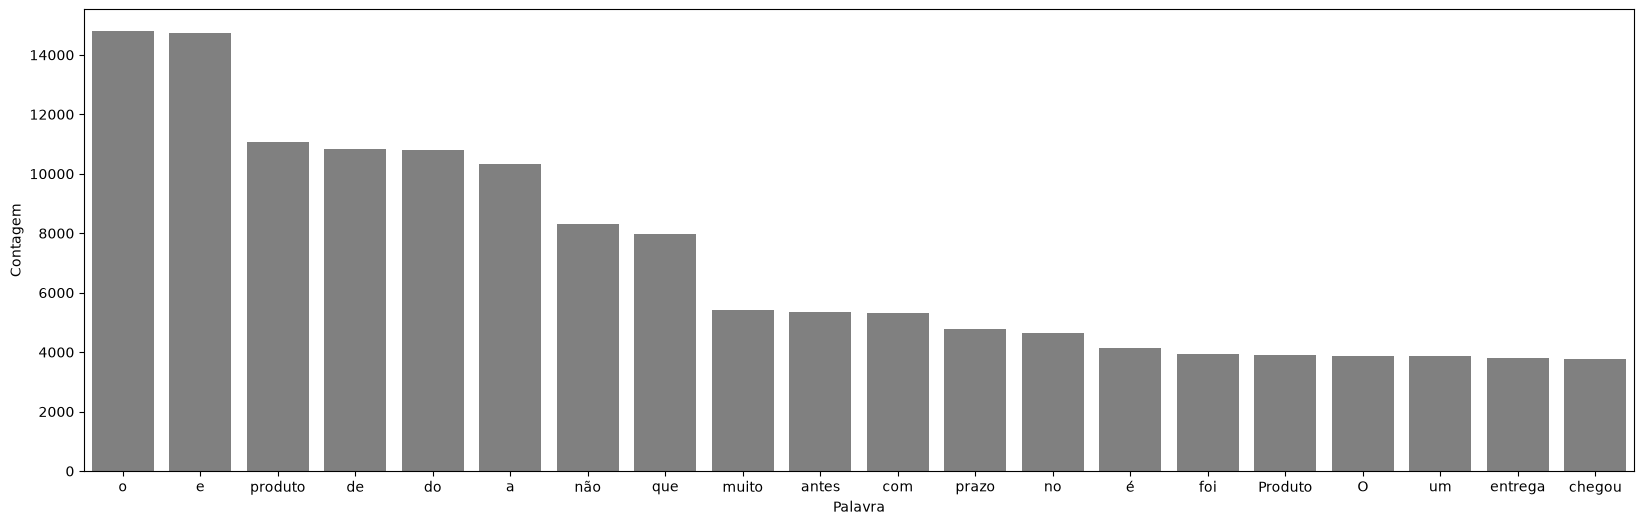

In [20]:
grafico_frequencia(mensagens, 'review', 20)

In [21]:
#REMOVER AS STOP WORDS

stop_words = nltk.corpus.stopwords.words('portuguese')
len(stop_words)


frase_processada = []

for review in mensagens.review:
    palavra_texto = token_espaco.tokenize(review)
    nova_frase = [palavra for palavra in palavra_texto if palavra not in stop_words]
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_1'] = frase_processada

In [22]:
#REMOVER PONTUAÇÃO

token_pontuacao = tokenize.WordPunctTokenizer()
frase_processada = []

for review in mensagens['tratamento_1']:
    palavras_texto = token_pontuacao.tokenize(review)
    nova_frase = [palavra for palavra in palavras_texto if 
    palavra.isalpha() and palavra not in stop_words]  #isalpha serve para pegar palavras do alfabeto
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_2'] = frase_processada

In [23]:
#remover acentos

import unidecode

sem_acentos = [unidecode.unidecode(texto) for texto in mensagens['tratamento_2']]
stopwords_sem_acento = [unidecode.unidecode(texto) for texto in stop_words]

In [24]:
mensagens['tratamento_3'] = sem_acentos

frase_processada = []

for avaliacao in mensagens['tratamento_3']:
    palavras_texto = token_pontuacao.tokenize(avaliacao)
    nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
    frase_processada.append(' '.join(nova_frase))


mensagens['tratamento_3'] = frase_processada


In [25]:
#Transformar em Lower Case

frase_processada = []

for opiniao in mensagens['tratamento_3']:
    opiniao = opiniao.lower()
    palavras_texto = token_pontuacao.tokenize(opiniao)
    nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_4'] = frase_processada

In [26]:
mensagens.head(2).T

,3,4
order_id,658677c97b385a9be170737859d3511b,8e6bfb81e283fa7e4f11123a3fb894f1
review,Recebi bem antes do prazo estipulado.,Parabéns lojas lannister adorei comprar pela I...
avaliacao,positiva,positiva
tratamento_1,Recebi bem antes prazo estipulado.,Parabéns lojas lannister adorei comprar Intern...
tratamento_2,Recebi bem antes prazo estipulado,Parabéns lojas lannister adorei comprar Intern...
tratamento_3,Recebi bem antes prazo estipulado,Parabens lojas lannister adorei comprar Intern...
tratamento_4,recebi bem antes prazo estipulado,parabens lojas lannister adorei comprar intern...


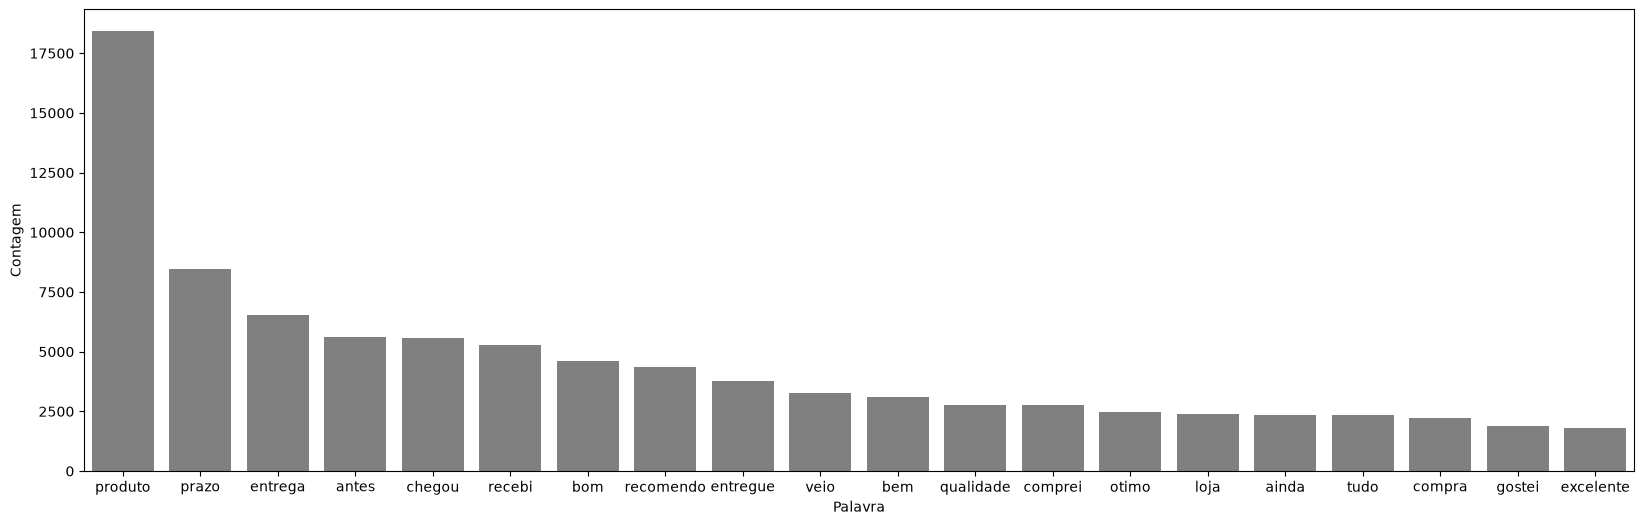

In [27]:
grafico_frequencia(mensagens, 'tratamento_4', 20)

fizemos a limpeza, isso ajudará caso o problema seja fazer um programa de avaliação das categorias, entretanto para limpeza em RAG devemos seguir um padrão que não dificulte gere problemas semanticos nas frases 

mas faremos um modelo para avaliar novas classificações 

In [ ]:
import joblib
from pathlib import Path
import nltk
from nltk.tokenize import RegexpTokenizer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, accuracy_score

#  Criação do tratamento_5 (Stemming com RSLP para português)
nltk.download('rslp', quiet=True)
stemmer = nltk.RSLPStemmer()
token_pontuacao = RegexpTokenizer(r'\w+')

frase_processada = []
for avaliacao in mensagens['tratamento_4']:
    palavra_texto = token_pontuacao.tokenize(str(avaliacao))
    nova_frase = [stemmer.stem(palavra) for palavra in palavra_texto]
    frase_processada.append(' '.join(nova_frase))

mensagens['tratamento_5'] = frase_processada

#  Divisão em Treino e Teste (evitando vazamento de dados)
X = mensagens['tratamento_5']
y = mensagens['avaliacao']  # 'positiva' ou 'negativa'

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, 
    test_size=0.20, 
    random_state=4978, 
    stratify=y
)

#  Construção do Pipeline (TF-IDF + Regressão Logística)
pipeline_classificador = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('classificador', LogisticRegression(max_iter=1000, random_state=42))
])

# Treinamento
pipeline_classificador.fit(X_treino, y_treino)

# Avaliação do Modelo
y_pred = pipeline_classificador.predict(X_teste)
acuracia = accuracy_score(y_teste, y_pred)

print(f" Acurácia do Modelo: {acuracia * 100:.2f}%\n")
print("Relatório de Classificação Detalhado:")
print(classification_report(y_teste, y_pred))

#  Salvar o modelo treinado para uso no Streamlit
# caminho_modelo = project_root / "fase_4" / "models" / "classificador_sentimento.pkl"
# joblib.dump(pipeline_classificador, caminho_modelo)
# print(f" Modelo salvo com sucesso em: {caminho_modelo}")


 Acurácia do Modelo: 89.10%

Relatório de Classificação Detalhado:
              precision    recall  f1-score   support

    negativa       0.85      0.84      0.84      2890
    positiva       0.91      0.92      0.92      5306

    accuracy                           0.89      8196
   macro avg       0.88      0.88      0.88      8196
weighted avg       0.89      0.89      0.89      8196

 Modelo salvo com sucesso em: C:\Users\deth_\Carmel Capital\TECNOLOGIA - Geral\LUCAS\Estudos\FIAP\POSTECH_AI_SCIENTIST\tech_challenge_04\fase_4\models\classificador_sentimento.pkl


Agora  iremos enriquecer a base, depois faremos uma nova limpeza

### Enriquecimento da base

In [ ]:
import pandas as pd

# 1. Utiliza a sua base já tratada 'mensagens'
df_reviews_com_texto = mensagens.copy()

# Se faltar 'review_id' ou 'review_score' no mensagens, resgatamos via merge pelo order_id:
colunas_necessarias = {'review_id', 'review_score'}
if not colunas_necessarias.issubset(df_reviews_com_texto.columns):
    df_reviews_com_texto = df_reviews_com_texto.merge(
        dfs['olist_order_reviews_dataset'][['order_id', 'review_id', 'review_score']],
        on='order_id',
        how='left'
    )

# 2. Calcular se houve atraso de entrega na tabela de orders
df_orders = dfs['olist_orders_dataset'].copy()
df_orders['order_delivered_customer_date'] = pd.to_datetime(df_orders['order_delivered_customer_date'])
df_orders['order_estimated_delivery_date'] = pd.to_datetime(df_orders['order_estimated_delivery_date'])

# Dias de atraso (positivo = atrasou; zero ou negativo = no prazo/adiantado)
df_orders['dias_atraso'] = (df_orders['order_delivered_customer_date'] - df_orders['order_estimated_delivery_date']).dt.days
df_orders['entregue_com_atraso'] = df_orders['dias_atraso'] > 0

# 3. Consolidar categoria dos produtos por order_id evitando duplicar os itens 
df_items_prod = dfs['olist_order_items_dataset'].merge(
    dfs['olist_products_dataset'][['product_id', 'product_category_name']], 
    on='product_id', 
    how='left'
)

df_produtos_por_pedido = df_items_prod.groupby('order_id').agg({
    'product_category_name': lambda cats: ', '.join(sorted(set(str(c) for c in cats.dropna() if str(c) != 'nan'))),
    'price': 'sum',
    'freight_value': 'sum',
    'product_id': 'count' # quantidade de itens
}).reset_index().rename(columns={'product_id': 'qtd_itens'})

# 4. Merge Final: Base Enriquecida para o RAG
df_rag_final = df_reviews_com_texto.merge(
    df_orders[['order_id', 'order_status', 'order_purchase_timestamp', 'dias_atraso', 'entregue_com_atraso']],
    on='order_id',
    how='inner'
).merge(
    df_produtos_por_pedido,
    on='order_id',
    how='left'
)

print(f"Base RAG criada com sucesso! Total de linhas: {len(df_rag_final)}")
display(df_rag_final[['order_id', 'review', 'avaliacao', 'product_category_name', 'entregue_com_atraso', 'dias_atraso']].head(3))


✅ Base RAG criada com sucesso! Total de linhas: 41367


,order_id,review,avaliacao,product_category_name,entregue_com_atraso,dias_atraso
0,658677c97b385a9be170737859d3511b,Recebi bem antes do prazo estipulado.,positiva,ferramentas_jardim,False,-20.0
1,8e6bfb81e283fa7e4f11123a3fb894f1,Parabéns lojas lannister adorei comprar pela I...,positiva,esporte_lazer,False,-9.0
2,b9bf720beb4ab3728760088589c62129,aparelho eficiente. no site a marca do aparelh...,positiva,eletroportateis,False,-16.0


In [128]:
import re

def limpar_texto_rag(texto):
    if not isinstance(texto, str) or not texto.strip():
        return ""
    
    # 1. Remove quebras de linha brutas (\r\n, \n, \t)
    texto = re.sub(r'[\r\n\t]+', ' ', texto)
    
    # 2. Normaliza pontuação excessiva (ex: !!!!!!!! -> !)
    texto = re.sub(r'!{2,}', '!', texto)
    texto = re.sub(r'\?{2,}', '?', texto)
    texto = re.sub(r'\.{2,}', '.', texto)
    
    # 3. Normaliza repetição excessiva de letras (ex: "boooom" -> "boom")
    texto = re.sub(r'([a-zA-ZáéíóúãõçÁÉÍÓÚÃÕÇ])\1{2,}', r'\1\1', texto)
    
    # 4. Remove múltiplos espaços em branco
    texto = re.sub(r'\s+', ' ', texto).strip()
    
    return texto

import re

def separar_pontuacao_colada(texto):
    if not isinstance(texto, str):
        return ""
    # Se tiver letra colada em pontuação colada em letra (ex: "bom.Produto" ou "vez,fiz")
    texto = re.sub(r'([a-zA-ZáéíóúãõçÁÉÍÓÚÃÕÇ])([.,;!?:])([a-zA-ZáéíóúãõçÁÉÍÓÚÃÕÇ])', r'\1\2 \3', texto)
    return texto


In [124]:


# 1. Combinar Título + Mensagem (resgatando do df_review original)
df_rag_final = df_rag_final.merge(
    dfs['olist_order_reviews_dataset'][['order_id', 'review_comment_title']],
    on='order_id',
    how='left'
)

# Cria o texto completo unindo título (quando houver) e mensagem
df_rag_final['texto_completo'] = df_rag_final.apply(
    lambda row: f"{row['review_comment_title']}. {row['review']}" 
    if pd.notna(row['review_comment_title']) and str(row['review_comment_title']).strip() 
    else row['review'],
    axis=1
)

# 2. Aplica a limpeza semântica para RAG
df_rag_final['review_rag'] = df_rag_final['texto_completo'].apply(limpar_texto_rag)

# 3. Filtro de qualidade: descartar reviews sem substância (menos de 3 palavras)
df_rag_final['qtd_palavras'] = df_rag_final['review_rag'].apply(lambda x: len(x.split()))
df_rag_final = df_rag_final[df_rag_final['qtd_palavras'] >= 3].copy()

print(f"Total de reviews ricos prontos para Embeddings: {len(df_rag_final)}")
display(df_rag_final[['review', 'review_rag', 'qtd_palavras', 'avaliacao', 'product_category_name']].head(5))


Total de reviews ricos prontos para Embeddings: 37257


,review,review_rag,qtd_palavras,avaliacao,product_category_name
0,Recebi bem antes do prazo estipulado.,Recebi bem antes do prazo estipulado.,6,positiva,ferramentas_jardim
1,Parabéns lojas lannister adorei comprar pela I...,Parabéns lojas lannister adorei comprar pela I...,15,positiva,esporte_lazer
2,aparelho eficiente. no site a marca do aparelh...,recomendo. aparelho eficiente. no site a marca...,31,positiva,eletroportateis
3,"Mas um pouco ,travando...pelo valor ta Boa.\r\n","Mas um pouco ,travando.pelo valor ta Boa.",7,positiva,beleza_saude
4,"Vendedor confiável, produto ok e entrega antes...","Super recomendo. Vendedor confiável, produto o...",11,positiva,informatica_acessorios


Contar novamente as palavras 

In [ ]:
from nltk.tokenize import RegexpTokenizer


token_espaco = tokenize.WhitespaceTokenizer()

# Aplica a separação nos reviews
mensagens['review_separado'] = mensagens['review'].apply(separar_pontuacao_colada)
# 2. Tokenizer que extrai apenas palavras (sem pontuação grudada)
tokenizer_palavras = RegexpTokenizer(r'[a-zA-ZáéíóúãõçÁÉÍÓÚÃÕÇ]+')
# 3. Lista de Stopwords para a análise estatística
stop_words = set(nltk.corpus.stopwords.words('portuguese'))
# 4. Coleta todas as palavras tratadas em minúsculo
todas_palavras = []
for texto in mensagens['review_separado']:
    palavras = tokenizer_palavras.tokenize(texto.lower())
    # Opcional: ignorar palavras de 1 letra ou stopwords
    palavras_limpas = [p for p in palavras if p not in stop_words and len(p) > 1]
    todas_palavras.extend(palavras_limpas)
# 5. Calcula a frequência real
frequencia = nltk.FreqDist(todas_palavras)
df_frequencia = pd.DataFrame({
    'Palavra': list(frequencia.keys()),
    'Frequencia': list(frequencia.values())
}).sort_values(by='Frequencia', ascending=False).reset_index(drop=True)
print(f"Total de palavras únicas reais: {len(df_frequencia)}")
display(df_frequencia.head(20))

Total de palavras únicas reais: 14807


,Palavra,Frequencia
0,produto,18429
1,prazo,8475
2,entrega,6532
3,antes,5626
4,chegou,5555
5,recebi,5275
6,bom,4607
7,recomendo,4337
8,entregue,3779
9,veio,3285


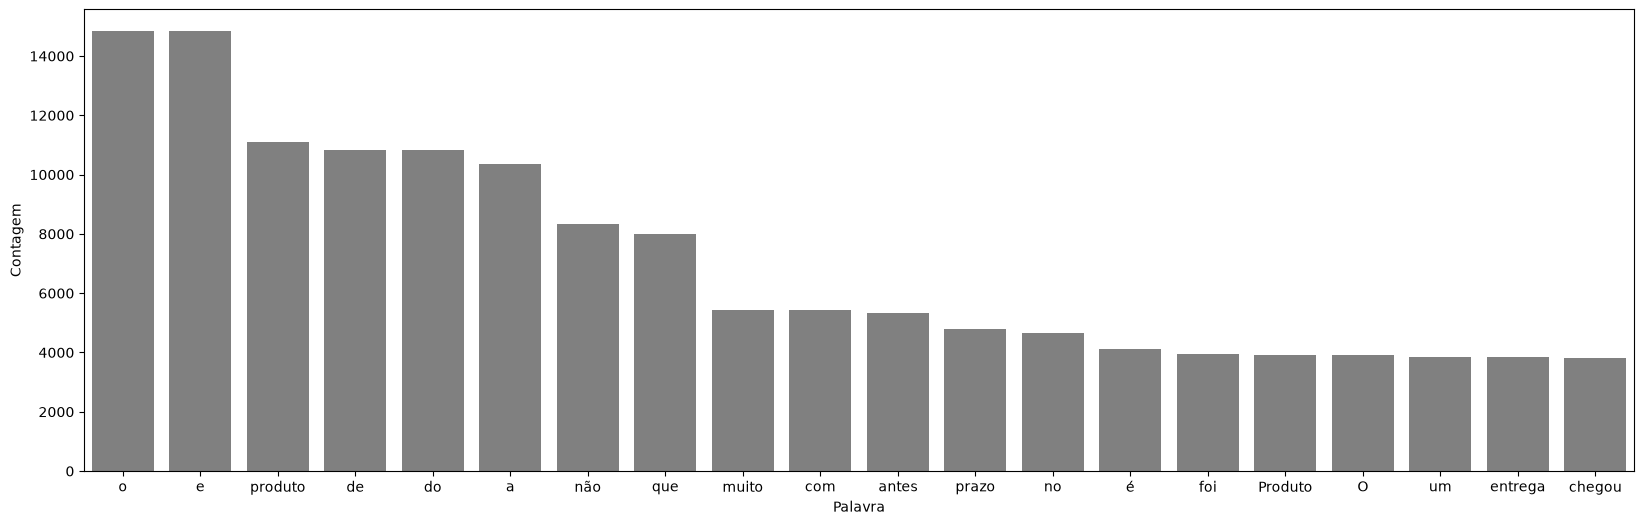

In [133]:
grafico_frequencia(mensagens, 'review_separado', 20)

In [ ]:
mensagens

,order_id,review,avaliacao,tratamento_1,tratamento_2,tratamento_3,tratamento_4,review_separado
3,658677c97b385a9be170737859d3511b,Recebi bem antes do prazo estipulado.,positiva,Recebi bem antes prazo estipulado.,Recebi bem antes prazo estipulado,Recebi bem antes prazo estipulado,recebi bem antes prazo estipulado,Recebi bem antes do prazo estipulado.
4,8e6bfb81e283fa7e4f11123a3fb894f1,Parabéns lojas lannister adorei comprar pela I...,positiva,Parabéns lojas lannister adorei comprar Intern...,Parabéns lojas lannister adorei comprar Intern...,Parabens lojas lannister adorei comprar Intern...,parabens lojas lannister adorei comprar intern...,Parabéns lojas lannister adorei comprar pela I...
9,b9bf720beb4ab3728760088589c62129,aparelho eficiente. no site a marca do aparelh...,positiva,aparelho eficiente. site marca aparelho impres...,aparelho eficiente site marca aparelho impress...,aparelho eficiente site marca aparelho impress...,aparelho eficiente site marca aparelho impress...,aparelho eficiente. no site a marca do aparelh...
12,9d6f15f95d01e79bd1349cc208361f09,"Mas um pouco ,travando...pelo valor ta Boa.\r\n",positiva,"Mas pouco ,travando...pelo valor ta Boa.",Mas pouco travando valor ta Boa,Mas pouco travando valor ta Boa,pouco travando valor ta boa,"Mas um pouco ,travando...pelo valor ta Boa.\r\n"
15,e51478e7e277a83743b6f9991dbfa3fb,"Vendedor confiável, produto ok e entrega antes...",positiva,"Vendedor confiável, produto ok entrega antes p...",Vendedor confiável produto ok entrega antes prazo,Vendedor confiavel produto ok entrega antes prazo,vendedor confiavel produto ok entrega antes prazo,"Vendedor confiável, produto ok e entrega antes..."
...,...,...,...,...,...,...,...,...
99205,d398e9c82363c12527f71801bf0e6100,para este produto recebi de acordo com a compr...,positiva,produto recebi acordo compra realizada!,produto recebi acordo compra realizada,produto recebi acordo compra realizada,produto recebi acordo compra realizada,para este produto recebi de acordo com a compr...
99208,509b86c65fe4e2ad5b96408cfef9755e,Entregou dentro do prazo. O produto chegou em ...,positiva,Entregou dentro prazo. O produto chegou condiç...,Entregou dentro prazo O produto chegou condiçõ...,Entregou dentro prazo O produto chegou condico...,entregou dentro prazo produto chegou condicoes...,Entregou dentro do prazo. O produto chegou em ...
99215,d5cb12269711bd1eaf7eed8fd32a7c95,"O produto não foi enviado com NF, não existe v...",negativa,"O produto enviado NF, existe venda NF, certeza...",O produto enviado NF existe venda NF certeza f...,O produto enviado NF existe venda NF certeza f...,produto enviado nf existe venda nf certeza fic...,"O produto não foi enviado com NF, não existe v..."
99221,55d4004744368f5571d1f590031933e4,"Excelente mochila, entrega super rápida. Super...",positiva,"Excelente mochila, entrega super rápida. Super...",Excelente mochila entrega super rápida Super r...,Excelente mochila entrega super rapida Super r...,excelente mochila entrega super rapida super r...,"Excelente mochila, entrega super rápida. Super..."


In [ ]:
from src.utils import salvar_parquet_s3, listar_arquivos_s3

# 1. Definir a chave de destino na camada Silver
chave_silver_mensagens = 'silver/mensagens.parquet'

print(f"Salvando 'mensagens' ({len(mensagens)} registros) em s3://{BUCKET_NAME}/{chave_silver_mensagens}...")

#Salvar
salvar_parquet_s3(
    df=mensagens,
    s3_client=s3_client,
    bucket=BUCKET_NAME,
    chave=chave_silver_mensagens
)


if 'df_rag_final' in locals():
    chave_silver_rag = 'silver/reviews_enriquecidos.parquet'
    print(f"\nSalvando 'df_rag_final' ({len(df_rag_final)} registros) em s3://{BUCKET_NAME}/{chave_silver_rag}...")
    salvar_parquet_s3(
        df=df_rag_final,
        s3_client=s3_client,
        bucket=BUCKET_NAME,
        chave=chave_silver_rag
    )


print("\n Arquivos confirmados na camada SILVER:")
for arq in listar_arquivos_s3(s3_client, BUCKET_NAME, prefixo='silver/'):
    print(f"  - s3://{BUCKET_NAME}/{arq}")


Salvando 'mensagens' (40977 registros) em s3://postech-challenge-datascience-004/silver/mensagens.parquet...
Salvo no S3: s3://postech-challenge-datascience-004/silver/mensagens.parquet

Salvando 'df_rag_final' (37257 registros) em s3://postech-challenge-datascience-004/silver/reviews_enriquecidos.parquet...
Salvo no S3: s3://postech-challenge-datascience-004/silver/reviews_enriquecidos.parquet

📂 Arquivos confirmados na camada SILVER:
  - s3://postech-challenge-datascience-004/silver/mensagens.parquet
  - s3://postech-challenge-datascience-004/silver/reviews_enriquecidos.parquet
